#Predict Students' Dropout and Academic Success

# Introduction

Student dropout is a significant challenge faced by educational institutions worldwide. High dropout rates not only affect students' academic and professional futures but also impact institutional performance, resource allocation, and overall educational effectiveness. Identifying students who are at risk of dropping out at an early stage can help institutions implement targeted support strategies and improve student retention rates.

The objective of this project is to develop a machine learning-based predictive system capable of identifying student outcomes using demographic, academic, financial, and socio-economic factors. By analyzing patterns in historical student records, the study aims to understand the key determinants of academic success and student attrition.

Through Exploratory Data Analysis (EDA), feature analysis, and predictive modeling, this project seeks to answer the following questions:

* Which factors have the strongest influence on student dropout and academic success?
* Can machine learning models accurately predict student outcomes?
* Which predictive model performs best for this classification problem?

The insights generated from this analysis can assist educational institutions in identifying at-risk students and implementing timely interventions to improve retention and graduation rates.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/student_dropout.csv")

print("Loaded csv")

Loaded csv


In [ ]:
df.shape

(4424, 37)

In [ ]:
df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


### Displaying the First Five Records of the Dataset

**What are we doing?**
We are using the `df.head()` function to display the first five rows of the dataset. This provides a quick preview of the data, including the available features, their values, and the overall structure of the dataset.

**Why are we doing it?**
Before performing any analysis, it is important to understand the dataset's layout and contents. Viewing the first few records helps verify that the dataset has been loaded correctly and allows us to identify the types of information available for analysis, such as demographic, academic, and financial attributes of students.

**What have we inferred?**
From the output, we observed that the dataset contains multiple features related to student demographics, academic performance, enrollment details, and financial status, along with the target variable representing the student's final outcome (Graduate, Dropout, or Enrolled). The data appears to be structured properly, with each row representing an individual student record.

**Decision Taken**
Since the dataset was loaded successfully and the structure appears consistent, we proceeded to perform further exploratory analysis to understand the dimensions, data types, quality, and distribution of the data.


In [ ]:
df.describe()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,...,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,1.178571,18.669078,1.727848,8856.642631,0.890823,4.577758,132.613314,1.873192,19.561935,22.275316,...,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,0.605747,17.484682,1.313793,2063.566416,0.311897,10.216592,13.188332,6.914514,15.603186,15.343108,...,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,1.000000,1.000000,0.000000,33.000000,0.000000,1.000000,95.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,1.000000,9085.000000,1.000000,1.000000,125.000000,1.000000,2.000000,3.000000,...,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,1.000000,17.000000,1.000000,9238.000000,1.000000,1.000000,133.100000,1.000000,19.000000,19.000000,...,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,1.000000,39.000000,2.000000,9556.000000,1.000000,1.000000,140.000000,1.000000,37.000000,37.000000,...,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,6.000000,57.000000,9.000000,9991.000000,1.000000,43.000000,190.000000,109.000000,44.000000,44.000000,...,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


### Statistical Summary of Numerical Features

**What are we doing?**
We are using the `df.describe()` function to generate descriptive statistics for all numerical features in the dataset. This includes measures such as count, mean, standard deviation, minimum value, maximum value, and quartiles (25%, 50%, and 75%).

**Why are we doing it?**
Descriptive statistics provide a high-level understanding of the numerical attributes in the dataset. They help identify the range of values, central tendency, variability, and potential anomalies or outliers. This step is important for understanding the characteristics of the data before performing detailed exploratory analysis and model building.

**What have we inferred?**
The summary statistics revealed the distribution of various numerical features such as admission grades, age at enrollment, curricular unit grades, and economic indicators. The presence of differences between the mean and median in some variables suggests possible skewness in their distributions. Additionally, the wide ranges observed in certain features indicate the presence of diverse student profiles within the dataset.

**Decision Taken**
Based on the statistical summary, we decided to further investigate the distribution of important features through visualization techniques such as histograms and boxplots. This helped us identify patterns, understand feature behavior, and detect any potential outliers that could influence model performance.


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance	                     4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                   

### Dataset Structure and Data Type Inspection

**What are we doing?**
We are using the `df.info()` function to examine the overall structure of the dataset. This provides information about the total number of records, number of features, data types of each column, and the presence of non-null values.

**Why are we doing it?**
Before performing preprocessing and analysis, it is essential to understand the dataset's structure and verify that each feature has been loaded correctly. This step helps identify data types (integer, float, object, etc.), detect missing values, and determine whether any data type conversions or preprocessing steps will be required before model development.

**What have we inferred?**
The output showed the total number of observations and features available in the dataset. We observed that the dataset primarily consists of numerical variables, making it suitable for machine learning algorithms. Additionally, the non-null count for each feature confirmed whether any missing values were present. The data types also helped distinguish between continuous, discrete, and categorical attributes.

**Decision Taken**
Based on the information obtained, we verified that the dataset structure was appropriate for further analysis. Since the majority of features were already in numerical format and no major data type inconsistencies were observed, we proceeded with data quality checks such as missing value analysis and duplicate record detection before conducting exploratory data analysis.


In [ ]:
df.isnull().sum()

,0
Marital status,0
Application mode,0
Application order,0
Course,0
Daytime/evening attendance\t,0
Previous qualification,0
Previous qualification (grade),0
Nacionality,0
Mother's qualification,0
Father's qualification,0


In [ ]:
duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates}")

Number of duplicate rows: 0


In [ ]:
print(df.columns)

Index(['Marital status', 'Application mode', 'Application order', 'Course',
       'Daytime/evening attendance\t', 'Previous qualification',
       'Previous qualification (grade)', 'Nacionality',
       'Mother's qualification', 'Father's qualification',
       'Mother's occupation', 'Father's occupation', 'Admission grade',
       'Displaced', 'Educational special needs', 'Debtor',
       'Tuition fees up to date', 'Gender', 'Scholarship holder',
       'Age at enrollment', 'International',
       'Curricular units 1st sem (credited)',
       'Curricular units 1st sem (enrolled)',
       'Curricular units 1st sem (evaluations)',
       'Curricular units 1st sem (approved)',
       'Curricular units 1st sem (grade)',
       'Curricular units 1st sem (without evaluations)',
       'Curricular units 2nd sem (credited)',
       'Curricular units 2nd sem (enrolled)',
       'Curricular units 2nd sem (evaluations)',
       'Curricular units 2nd sem (approved)',
       'Curricular units 2nd

### Missing Value Analysis

**What are we doing?**
We are using the `df.isnull().sum()` function to calculate the number of missing (null) values present in each feature of the dataset.

**Why are we doing it?**
Missing values can significantly impact the quality of analysis and the performance of machine learning models. Many algorithms cannot handle null values directly, making it necessary to identify and address them before proceeding with data preprocessing and model training. This step helps determine whether data imputation, replacement, or removal techniques are required.

**What have we inferred?**
The output showed the number of missing values for every feature in the dataset. We observed that all columns contained zero missing values, indicating that the dataset is complete and does not suffer from data loss or incomplete records.

**Decision Taken**
Since no missing values were found, no imputation or missing-value treatment was required. This allowed us to proceed directly to the next data quality checks, such as duplicate record analysis, without introducing any additional preprocessing steps.


In [ ]:
# Dataset overview
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Missing values
missing = df.isnull().sum()
print("\nMissing Values:")
print(missing[missing > 0])

# Duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Unique values per column
unique_counts = df.nunique()

unique_df = pd.DataFrame({
    'Column': unique_counts.index,
    'Unique Values': unique_counts.values
})

unique_df.sort_values("Unique Values")

Rows: 4424
Columns: 37

Missing Values:
Series([], dtype: int64)

Duplicate Rows: 0


,Column,Unique Values
4,Daytime/evening attendance\t,2
13,Displaced,2
15,Debtor,2
14,Educational special needs,2
20,International,2
18,Scholarship holder,2
17,Gender,2
16,Tuition fees up to date,2
36,Target,3
0,Marital status,6


### Dataset Quality and Cardinality Analysis

**What are we doing?**
In this step, we are performing a comprehensive overview of the dataset by examining its dimensions, checking for missing values, identifying duplicate records, and calculating the number of unique values present in each feature.

**Why are we doing it?**
Before conducting exploratory data analysis or building predictive models, it is important to assess the overall quality and structure of the dataset. The number of rows and columns provides an understanding of dataset size, while missing value and duplicate checks help identify potential data quality issues. Additionally, analyzing the number of unique values in each feature helps distinguish between categorical, binary, and continuous variables, which is essential for selecting appropriate preprocessing and visualization techniques.

**What have we inferred?**
The dataset contains a sufficient number of student records and features for analysis. No missing values were detected, indicating complete data availability across all attributes. Furthermore, no duplicate records were found, suggesting that each observation represents a unique student. The unique value analysis revealed that some variables contain only a few distinct values (binary or categorical features), while others contain many unique values (continuous numerical features). This provided valuable insight into the nature of each feature and guided subsequent exploratory analysis.

**Decision Taken**
Since the dataset was free from missing values and duplicate records, no additional cleaning was required. Based on the unique value counts, we identified which variables should be treated as categorical features during visualization and interpretation, and which variables should be analyzed using statistical and numerical methods. This understanding informed our choice of EDA techniques in the following stages of the project.


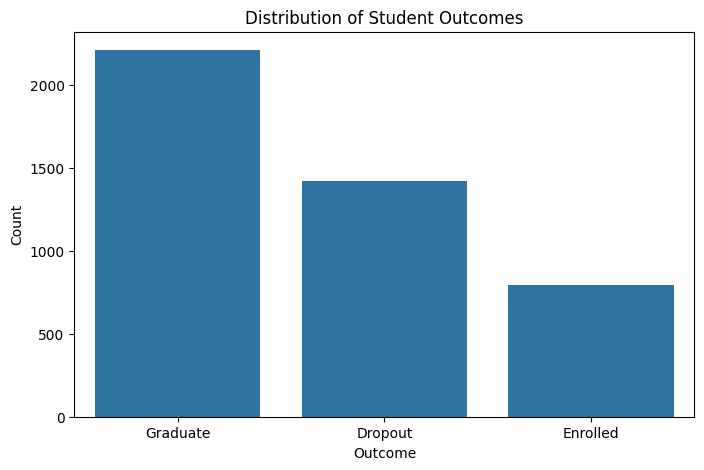

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='Target',
    data=df,
    order=df['Target'].value_counts().index
)

plt.title('Distribution of Student Outcomes')
plt.xlabel('Outcome')
plt.ylabel('Count')

plt.show()

### Distribution of Student Outcomes

**What are we doing?**
We are creating a count plot of the target variable (`Target`) to visualize the number of students belonging to each outcome category: Graduate, Dropout, and Enrolled.

**Why are we doing it?**
Since the objective of this project is to predict student outcomes, it is essential to first understand the distribution of the target variable. This helps determine whether the dataset is balanced or imbalanced and provides insight into the prevalence of each outcome category. Understanding the target distribution is also important when selecting evaluation metrics and machine learning techniques.

**What have we inferred?**
The visualization revealed that the largest group of students successfully graduated, followed by students who dropped out, while the smallest group consisted of students who were still enrolled. The distribution indicates that although the classes are not perfectly balanced, there is sufficient representation of all outcome categories for classification modeling.

**Decision Taken**
Since all three target classes contain a substantial number of observations, we decided to proceed with multiclass classification without applying any class-balancing techniques at this stage. The presence of a significant dropout population also confirms the practical relevance of building a predictive model to identify students at risk of leaving their studies prematurely.


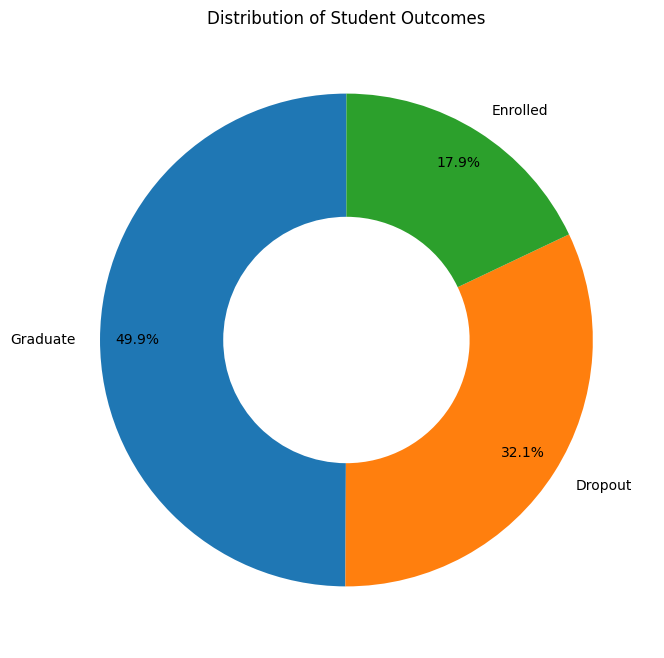

In [ ]:
outcome_percent = df['Target'].value_counts(normalize=True) * 100
plt.figure(figsize=(8,8))

plt.pie(
    outcome_percent.values,
    labels=outcome_percent.index,
    autopct='%1.1f%%',
    pctdistance=0.85,
    startangle=90,
    wedgeprops=dict(width=0.5)
)

plt.title('Distribution of Student Outcomes')
plt.show()

### Percentage Distribution of Student Outcomes

**What are we doing?**
We are calculating the percentage distribution of the target variable (`Target`) and visualizing it using a donut chart. The chart displays the proportion of students who graduated, dropped out, or remained enrolled.

**Why are we doing it?**
While the previous count plot showed the absolute number of students in each category, percentage-based visualization provides a clearer understanding of the relative composition of the dataset. This helps evaluate the balance of the target classes and assess whether any outcome category dominates the dataset.

**What have we inferred?**
The donut chart revealed that approximately 49.9% of students graduated, 32.1% dropped out, and 17.9% remained enrolled. This indicates that nearly one-third of the student population failed to complete their studies, highlighting the significance of the dropout prediction problem. Although the classes are not perfectly balanced, all categories are adequately represented within the dataset.

**Decision Taken**
Since the target classes are reasonably represented, we decided to proceed with multiclass classification without applying resampling techniques such as oversampling or undersampling. The substantial proportion of dropout cases further justifies the need for identifying the factors that contribute to student attrition in subsequent exploratory analysis.


In [ ]:
df['Age at enrollment'].describe()

,Age at enrollment
count,4424.000000
mean,23.265145
std,7.587816
min,17.000000
25%,19.000000
50%,20.000000
75%,25.000000
max,70.000000


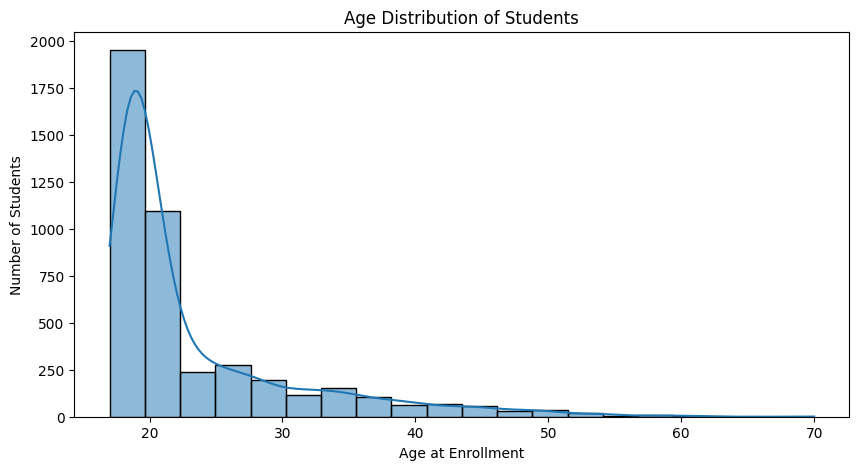

In [ ]:
plt.figure(figsize=(10,5))

sns.histplot(
    df['Age at enrollment'],
    bins=20,
    kde=True
)

plt.title('Age Distribution of Students')
plt.xlabel('Age at Enrollment')
plt.ylabel('Number of Students')

plt.show()

### Distribution of Students by Age at Enrollment

**What are we doing?**
We are visualizing the distribution of the `Age at enrollment` feature using a histogram combined with a Kernel Density Estimation (KDE) curve. The histogram shows the frequency of students across different age groups, while the KDE curve provides a smooth representation of the overall distribution.

**Why are we doing it?**
Age is an important demographic factor that may influence a student's academic journey and likelihood of graduation or dropout. Understanding the age distribution helps identify the dominant age groups within the dataset and determine whether age should be considered a potentially influential feature during predictive modeling.

**What have we inferred?**
The distribution indicates that the majority of students enrolled at a relatively young age, with a strong concentration around the late teenage and early twenties age range. As age increases, the number of students decreases significantly, resulting in a positively skewed distribution. The presence of a smaller number of older students suggests that the dataset contains both traditional and non-traditional learners.

**Decision Taken**
Since age exhibits variation across the student population and represents a potentially meaningful demographic characteristic, we decided to investigate its relationship with student outcomes in subsequent analysis. This motivated further visualizations comparing age distributions across the Graduate, Dropout, and Enrolled categories to determine whether age influences student retention and success.


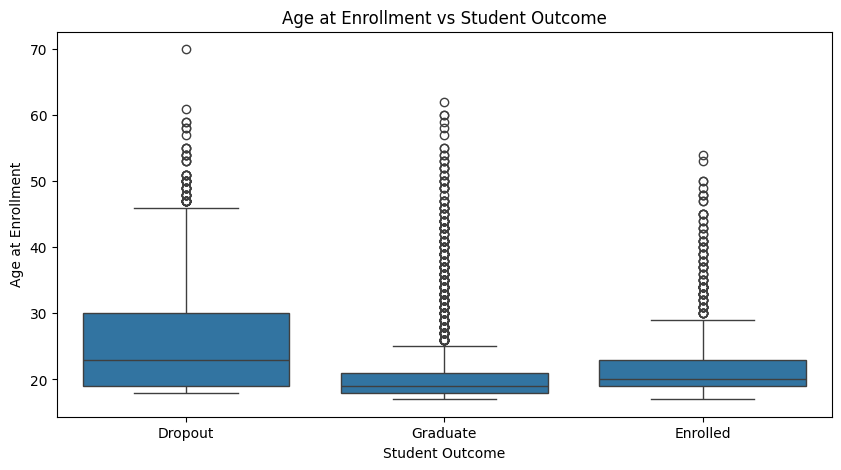

In [ ]:
plt.figure(figsize=(10,5))

sns.boxplot(
    x='Target',
    y='Age at enrollment',
    data=df
)

plt.title('Age at Enrollment vs Student Outcome')
plt.xlabel('Student Outcome')
plt.ylabel('Age at Enrollment')

plt.show()

### Relationship Between Age at Enrollment and Student Outcome

**What are we doing?**
We are using a boxplot to compare the distribution of `Age at enrollment` across the three student outcome categories: Graduate, Dropout, and Enrolled. The boxplot displays the median, quartiles, spread of the data, and potential outliers for each group.

**Why are we doing it?**
While the previous histogram showed the overall age distribution of students, it did not reveal whether age is associated with student success or dropout. By comparing age distributions across outcome categories, we can determine whether certain age groups are more likely to graduate or leave their studies prematurely.

**What have we inferred?**
The boxplot revealed noticeable differences in age distributions among the three outcome groups. Students who graduated generally enrolled at a younger age, whereas students who dropped out tended to be older at the time of enrollment. The dropout group also exhibited a wider age range, indicating greater variability in student backgrounds. This suggests that age may be associated with student retention and academic success.

**Decision Taken**
Since age appears to show a relationship with student outcomes, we retained it as a potentially important predictive feature for the classification model. However, the overlap between the age distributions indicates that age alone is unlikely to explain dropout behavior and should be analyzed alongside academic and financial factors in subsequent stages of the analysis.


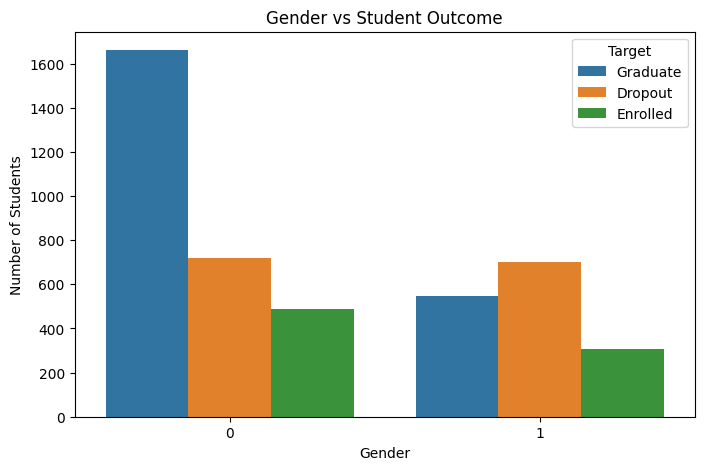

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='Gender',
    hue='Target',
    data=df
)

plt.title('Gender vs Student Outcome')
plt.xlabel('Gender')
plt.ylabel('Number of Students')

plt.show()

### Relationship Between Gender and Student Outcome

**What are we doing?**
We are creating a count plot to compare student outcomes across different gender groups. The visualization displays the number of students who graduated, dropped out, or remained enrolled for each gender category.

**Why are we doing it?**
Gender is an important demographic variable that may influence educational outcomes. By examining the distribution of student outcomes across genders, we can determine whether there are noticeable differences in graduation and dropout patterns. This helps identify whether gender should be considered a relevant factor in predicting student success.

**What have we inferred?**
The visualization revealed clear differences in outcome distributions between male and female students. Female students exhibited a higher proportion of graduates and a lower proportion of dropouts, whereas male students showed a comparatively higher dropout rate. This suggests that gender may have a meaningful relationship with student retention and academic achievement.

**Decision Taken**
Since noticeable differences were observed between gender groups, we retained gender as a potentially important predictor in the classification model. To validate and quantify these differences more accurately, we subsequently analyzed the percentage distribution of outcomes within each gender category rather than relying solely on absolute counts.


In [ ]:
pd.crosstab(
    df['Gender'], #F=0,M=1
    df['Target'],
    normalize='index'
) * 100

Target,Dropout,Enrolled,Graduate
Gender,,,
0,25.104603,16.980474,57.914923
1,45.051414,19.730077,35.218509


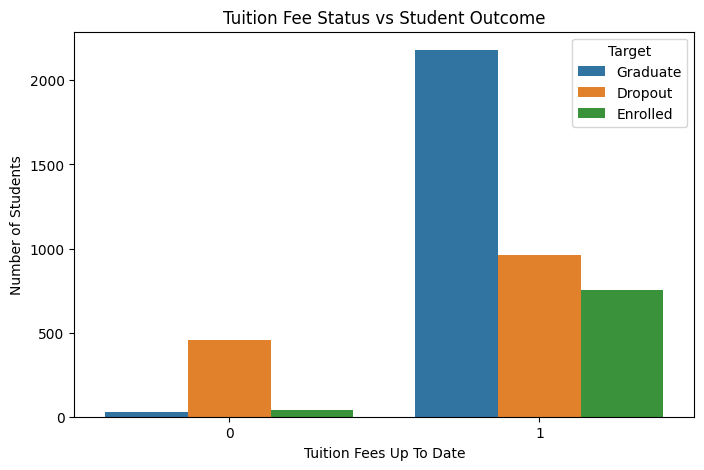

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='Tuition fees up to date',#0=No,1=Yes
    hue='Target',
    data=df
)

plt.title('Tuition Fee Status vs Student Outcome')
plt.xlabel('Tuition Fees Up To Date')
plt.ylabel('Number of Students')

plt.show()

### Relationship Between Tuition Fee Status and Student Outcome

**What are we doing?**
We are using a count plot to examine the relationship between the student's tuition fee payment status and their final academic outcome. The visualization compares the number of students who graduated, dropped out, or remained enrolled based on whether their tuition fees were up to date.

**Why are we doing it?**
Financial stability is often a significant factor influencing a student's ability to continue their education. Students facing financial difficulties may encounter barriers that affect their academic performance and persistence. By analyzing tuition fee status, we aim to determine whether financial obligations are associated with graduation or dropout outcomes.

**What have we inferred?**
The visualization revealed a strong relationship between tuition fee status and student outcomes. Students whose tuition fees were up to date showed a substantially higher number of graduates and a lower number of dropouts. In contrast, students with unpaid or overdue tuition fees exhibited a noticeably higher dropout rate. This suggests that financial difficulties may play a critical role in student attrition.

**Decision Taken**
Given the strong separation observed between the outcome groups, tuition fee status was identified as one of the most influential features in the dataset. We retained this variable as a key predictor for the classification model and further investigated other financial factors, such as scholarship status and debtor status, to better understand the impact of financial circumstances on student success.


In [ ]:
pd.crosstab(
    df['Tuition fees up to date'],#0=No,1=yes
    df['Target'],
    normalize='index'
) * 100

Target,Dropout,Enrolled,Graduate
Tuition fees up to date,,,
0,86.553030,7.954545,5.492424
1,24.743326,19.301848,55.954825


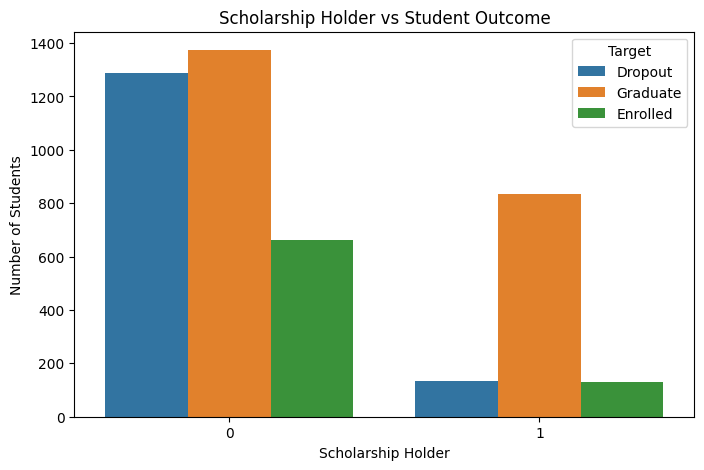

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='Scholarship holder',
    hue='Target',
    data=df
)

plt.title('Scholarship Holder vs Student Outcome')
plt.xlabel('Scholarship Holder')
plt.ylabel('Number of Students')

plt.show()

### Relationship Between Scholarship Status and Student Outcome

**What are we doing?**
We are creating a count plot to compare student outcomes based on scholarship status. The visualization shows the number of students who graduated, dropped out, or remained enrolled among scholarship recipients and non-recipients.

**Why are we doing it?**
Scholarships provide financial assistance that can reduce educational expenses and financial stress. Since financial factors have already shown a strong relationship with student outcomes, it is important to investigate whether receiving a scholarship is associated with improved graduation rates and reduced dropout rates.

**What have we inferred?**
The visualization revealed a clear difference between scholarship holders and non-scholarship students. Scholarship recipients showed a substantially higher number of graduates and a lower number of dropouts. In contrast, students without scholarships exhibited comparatively lower graduation rates and higher dropout rates. This suggests that financial support may positively influence student retention and academic success.

**Decision Taken**
Based on the observed relationship, scholarship status was identified as an important financial indicator and retained as a valuable predictor for the classification model. The findings reinforced our hypothesis that financial stability plays a significant role in determining student outcomes. Consequently, we continued exploring additional financial variables, such as debtor status, to further understand the impact of economic factors on dropout behavior.


In [ ]:
pd.crosstab(
    df['Scholarship holder'],#0=no,1=yes
    df['Target'],
    normalize='index'
) * 100

Target,Dropout,Enrolled,Graduate
Scholarship holder,,,
0,38.706767,19.969925,41.323308
1,12.192903,11.828935,75.978162


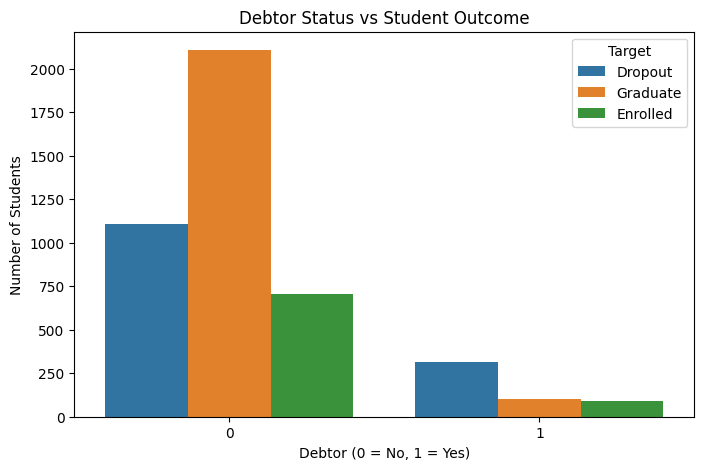

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='Debtor',
    hue='Target',
    data=df
)

plt.title('Debtor Status vs Student Outcome')
plt.xlabel('Debtor (0 = No, 1 = Yes)')
plt.ylabel('Number of Students')

plt.show()

### Relationship Between Debtor Status and Student Outcome

**What are we doing?**
We are creating a count plot to analyze the relationship between a student's debtor status and their final academic outcome. The visualization compares the number of students who graduated, dropped out, or remained enrolled among debtors and non-debtors.

**Why are we doing it?**
Previous analysis of tuition fee status and scholarship support indicated that financial factors may significantly influence student success. Debtor status is another important financial indicator that may reflect economic challenges faced by students. By examining this variable, we aim to determine whether students with outstanding debts are at a greater risk of dropping out.

**What have we inferred?**
The visualization revealed a clear difference between debtors and non-debtors. Students who were not debtors exhibited a higher number of graduates and a lower number of dropouts. In contrast, students with outstanding debt showed a substantially larger proportion of dropouts and fewer graduates. This pattern suggests that financial difficulties may negatively affect a student's ability to continue and successfully complete their studies.

**Decision Taken**
The strong relationship between debtor status and student outcome led us to retain this feature as an important predictor for the classification model. Combined with tuition fee status and scholarship information, debtor status strengthened the emerging evidence that financial stability is a major factor influencing student retention and graduation. This motivated us to continue exploring academic performance variables to determine whether academic and financial factors together explain student dropout behavior.


In [ ]:
pd.crosstab(
    df['Debtor'],
    df['Target'],
    normalize='index'
) * 100

Target,Dropout,Enrolled,Graduate
Debtor,,,
0,28.283601,17.954603,53.761795
1,62.027833,17.892644,20.079523


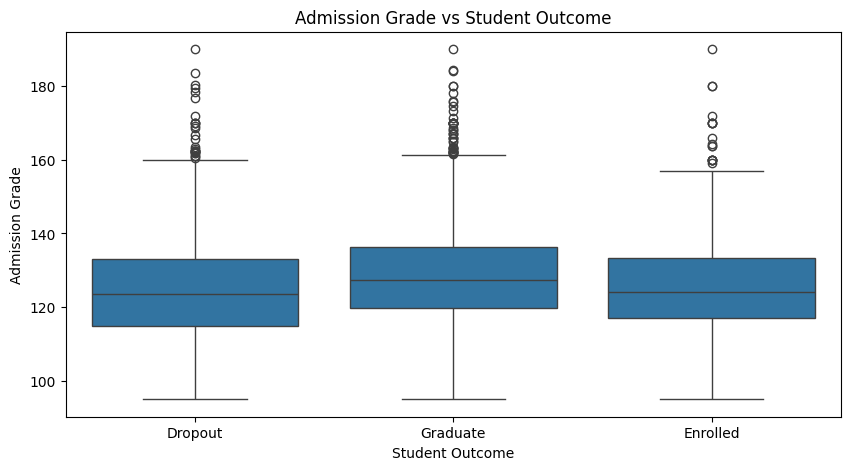

In [ ]:
plt.figure(figsize=(10,5))

sns.boxplot(
    x='Target',
    y='Admission grade',
    data=df
)

plt.title('Admission Grade vs Student Outcome')
plt.xlabel('Student Outcome')
plt.ylabel('Admission Grade')

plt.show()

### Relationship Between Admission Grade and Student Outcome

**What are we doing?**
We are using a boxplot to compare the distribution of admission grades across the three student outcome categories: Graduate, Dropout, and Enrolled. The boxplot displays the median, interquartile range, spread, and potential outliers for each group.

**Why are we doing it?**
Admission grade represents a student's academic performance before entering higher education. Since prior academic achievement may influence future success, it is important to investigate whether students who eventually graduate, remain enrolled, or drop out differ significantly in their admission scores.

**What have we inferred?**
The boxplot showed that students who graduated generally had slightly higher admission grades compared to students who dropped out. However, there was substantial overlap between the distributions of all three outcome groups. This indicates that while admission grade may have some influence on student success, it does not appear to be a strong standalone predictor of dropout or graduation.

**Decision Taken**
Although admission grade demonstrated a modest relationship with student outcomes, the overlap between groups suggests that it is less influential than the financial factors analyzed previously. We retained the feature for modeling purposes but decided to focus next on academic performance during university studies, such as semester grades and approved curricular units, as these were expected to provide stronger predictive signals regarding student dropout and graduation.


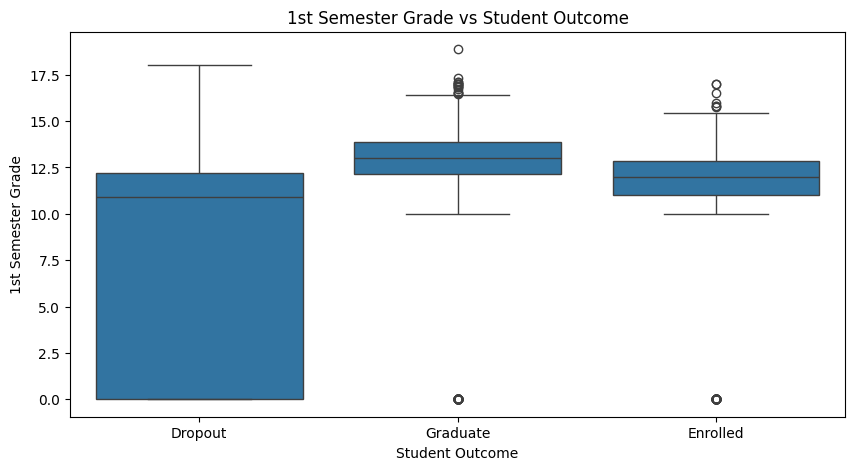

In [ ]:
plt.figure(figsize=(10,5))

sns.boxplot(
    x='Target',
    y='Curricular units 1st sem (grade)',
    data=df
)

plt.title('1st Semester Grade vs Student Outcome')
plt.xlabel('Student Outcome')
plt.ylabel('1st Semester Grade')

plt.show()

### Relationship Between First Semester Grade and Student Outcome

**What are we doing?**
We are using a boxplot to compare the distribution of first-semester grades across the three student outcome categories: Graduate, Dropout, and Enrolled. The visualization allows us to examine differences in academic performance during the first semester of study.

**Why are we doing it?**
The first semester represents a student's initial adjustment to higher education. Academic performance during this period may provide early indications of future success or academic difficulties. By analyzing first-semester grades, we aim to determine whether early academic achievement is associated with graduation or dropout outcomes.

**What have we inferred?**
The boxplot revealed a clear separation between the outcome groups. Students who graduated generally achieved higher first-semester grades, while students who dropped out had significantly lower grades and greater variability in performance. A notable proportion of dropout students recorded grades close to zero, indicating severe academic difficulties during the early stages of their studies. In contrast, graduate students demonstrated consistently stronger academic performance.

**Decision Taken**
The strong distinction between the groups suggests that first-semester grade is one of the most important predictors of student outcome. Unlike admission grade, which showed considerable overlap between categories, first-semester academic performance provides a much clearer signal regarding future success or dropout risk. Therefore, this feature was identified as a high-priority variable for predictive modeling, and we continued investigating additional academic performance indicators from subsequent semesters.


In [ ]:
df.groupby('Target')['Curricular units 1st sem (grade)'].describe()

,count,mean,std,min,25%,50%,75%,max
Target,,,,,,,,
Dropout,1421.0,7.256656,6.031120,0.0,0.000000,10.928571,12.200000,18.000
Enrolled,794.0,11.125257,3.675084,0.0,11.000000,12.000000,12.857143,17.000
Graduate,2209.0,12.643655,2.699027,0.0,12.121429,13.000000,13.857143,18.875


### Statistical Summary of First Semester Grades by Student Outcome

**What are we doing?**
We are generating descriptive statistics for the `Curricular units 1st sem (grade)` feature grouped by the target variable. The output provides key statistical measures such as count, mean, median, standard deviation, minimum, maximum, and quartiles for each student outcome category.

**Why are we doing it?**
While the boxplot provides a visual comparison of first-semester grades across outcome groups, descriptive statistics allow us to quantify these differences more precisely. This helps validate visual observations and identify specific performance patterns associated with graduation, enrollment, and dropout outcomes.

**What have we inferred?**
The statistical summary confirmed significant differences in first-semester academic performance among the three groups. Students who graduated achieved the highest average and median grades, while students who dropped out had the lowest academic performance. The dropout group also exhibited a larger standard deviation, indicating greater variability in performance. Most notably, the first quartile (25th percentile) for dropouts was equal to zero, indicating that at least 25% of dropout students achieved a first-semester grade of zero. This highlights severe academic difficulties among a substantial portion of students who eventually left their studies.

**Decision Taken**
The descriptive statistics reinforced the findings from the boxplot and confirmed that first-semester grade is one of the strongest indicators of student outcome. The clear performance gap between graduates and dropouts justified retaining this feature as a critical predictor for the classification model. Furthermore, the strong influence of early academic performance motivated us to investigate second-semester academic indicators to determine whether the predictive relationship became even stronger over time.


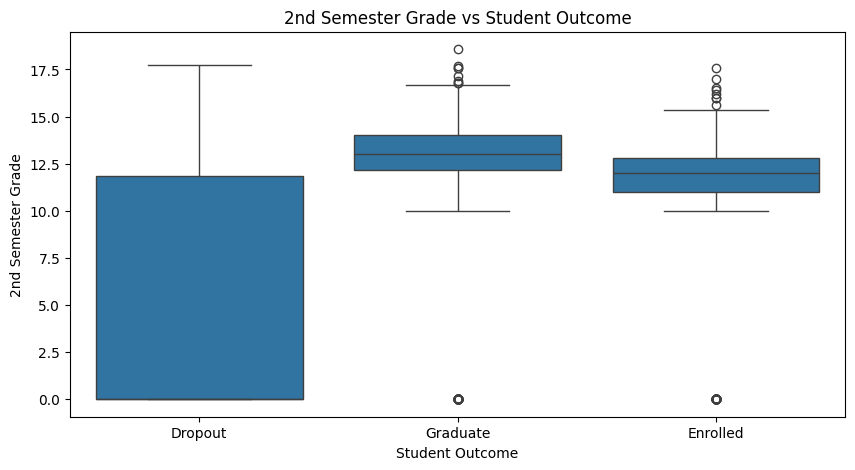

In [ ]:
plt.figure(figsize=(10,5))

sns.boxplot(
    x='Target',
    y='Curricular units 2nd sem (grade)',
    data=df
)

plt.title('2nd Semester Grade vs Student Outcome')
plt.xlabel('Student Outcome')
plt.ylabel('2nd Semester Grade')

plt.show()

### Relationship Between Second Semester Grade and Student Outcome

**What are we doing?**
We are using a boxplot to compare the distribution of second-semester grades across the three student outcome categories: Graduate, Dropout, and Enrolled. This visualization allows us to evaluate how academic performance during the second semester differs among students with different final outcomes.

**Why are we doing it?**
While first-semester grades provide insight into a student's initial academic adjustment, second-semester grades reflect whether the student was able to maintain, improve, or decline in performance over time. Analyzing second-semester grades helps determine whether sustained academic achievement is associated with graduation and whether poor performance is linked to dropout risk.

**What have we inferred?**
The boxplot revealed an even clearer separation between the outcome groups than observed in the first-semester analysis. Students who graduated consistently achieved higher second-semester grades, while dropout students exhibited substantially lower grades, with a large concentration of values near zero. The graduate group showed relatively stable performance with less variability, whereas the dropout group displayed greater dispersion and academic inconsistency. These findings indicate that second-semester academic performance is strongly associated with student success and retention.

**Decision Taken**
Given the strong distinction between graduates and dropouts, second-semester grade was identified as one of the most influential predictors in the dataset. The results suggest that continued academic performance after the first semester plays a crucial role in determining student outcomes. Consequently, this feature was retained as a key variable for model development, and further analysis was conducted on academic progression indicators such as approved curricular units to better understand the relationship between academic achievement and student retention.


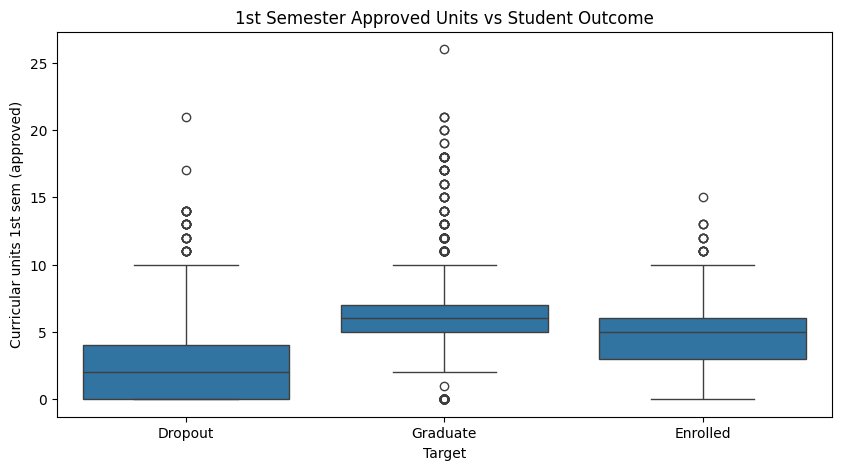

In [ ]:
plt.figure(figsize=(10,5))

sns.boxplot(
    x='Target',
    y='Curricular units 1st sem (approved)',
    data=df
)

plt.title('1st Semester Approved Units vs Student Outcome')
plt.show()

### Relationship Between First Semester Approved Curricular Units and Student Outcome

**What are we doing?**
We are using a boxplot to compare the number of curricular units approved (passed) during the first semester across the three student outcome categories: Graduate, Dropout, and Enrolled. This allows us to evaluate the extent of academic progress achieved by students during their initial semester.

**Why are we doing it?**
Grades provide information about academic performance, but they do not directly indicate whether students successfully completed their courses. The number of approved curricular units is a direct measure of academic progression and achievement. By analyzing this variable, we can determine whether students who pass more subjects in their first semester are more likely to graduate and less likely to drop out.

**What have we inferred?**
The boxplot revealed a substantial difference between the outcome groups. Students who graduated generally passed a higher number of curricular units during their first semester, whereas dropout students passed significantly fewer units. A considerable number of dropout students had very low or even zero approved units, indicating early academic difficulties. Enrolled students occupied an intermediate position between graduates and dropouts, reflecting moderate academic progress.

**Decision Taken**
The clear separation between the outcome groups suggests that the number of approved curricular units in the first semester is a strong indicator of future student success. This feature was therefore retained as a highly important predictor for the classification model. The findings also reinforced the conclusion that early academic achievement plays a critical role in student retention, motivating further analysis of second-semester approved units to assess whether the relationship becomes even stronger over time.


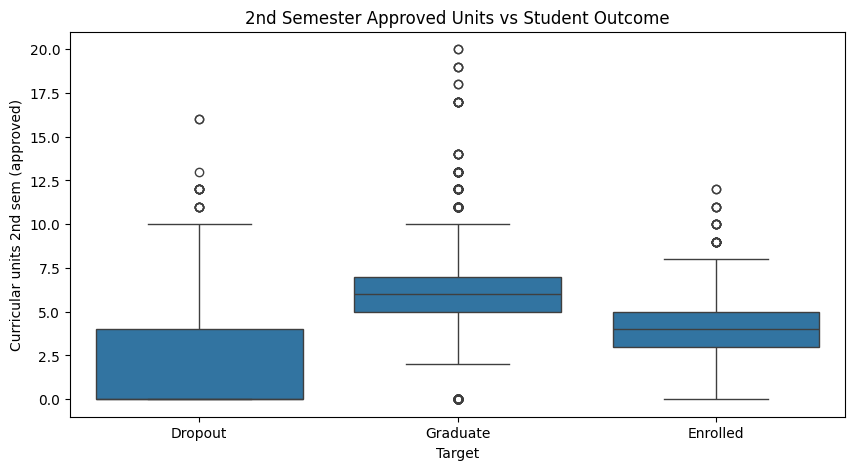

In [ ]:
plt.figure(figsize=(10,5))

sns.boxplot(
    x='Target',
    y='Curricular units 2nd sem (approved)',
    data=df
)

plt.title('2nd Semester Approved Units vs Student Outcome')
plt.show()

### Relationship Between Second Semester Approved Curricular Units and Student Outcome

**What are we doing?**
We are using a boxplot to compare the number of curricular units approved (passed) during the second semester across the three student outcome categories: Graduate, Dropout, and Enrolled. This visualization helps assess the level of academic progress students achieved after completing their first year of study.

**Why are we doing it?**
While first-semester approved units provide insight into a student's initial academic adjustment, second-semester approved units reflect whether the student was able to sustain academic progress over time. Since successful completion of courses is directly linked to degree progression, analyzing this variable can reveal whether continued academic achievement is associated with graduation or dropout outcomes.

**What have we inferred?**
The boxplot showed a very strong separation between the outcome groups. Students who graduated consistently passed a higher number of curricular units during the second semester, whereas dropout students passed very few or no units at all. The dropout group was heavily concentrated near zero approved units, indicating limited academic progression. Enrolled students demonstrated moderate performance, falling between graduates and dropouts. The distinction between the groups was even more pronounced than in the first-semester analysis.

**Decision Taken**
The strong separation observed in the boxplot indicates that second-semester approved units are among the most influential predictors of student outcomes. This feature was identified as a critical variable for the classification model, as it directly reflects a student's ability to progress academically. Combined with semester grades and financial indicators, this variable provided strong evidence that sustained academic performance is one of the primary determinants of graduation and dropout behavior.


In [ ]:
temp = df.copy()

temp['Target'] = temp['Target'].map({
    'Dropout': 0,
    'Enrolled': 1,
    'Graduate': 2
})

In [ ]:
corr_target = temp.corr(numeric_only=True)['Target'] \
                  .sort_values(ascending=False)

corr_target

,Target
Target,1.000000
Curricular units 2nd sem (approved),0.624157
Curricular units 2nd sem (grade),0.566827
Curricular units 1st sem (approved),0.529123
Curricular units 1st sem (grade),0.485207
Tuition fees up to date,0.409827
Scholarship holder,0.297595
Curricular units 2nd sem (enrolled),0.175847
Curricular units 1st sem (enrolled),0.155974
Admission grade,0.120889


### Correlation Analysis with the Target Variable

**What are we doing?**
We are calculating the correlation between each numerical feature and the target variable (`Target`). To perform this analysis, the target variable was temporarily encoded into numerical values, allowing us to measure the strength and direction of the relationship between each feature and student outcomes. The resulting correlations were then sorted in descending order.

**Why are we doing it?**
After analyzing individual variables through visualizations, it is important to quantify their relationship with the target variable. Correlation analysis helps identify which features are most strongly associated with graduation, enrollment, or dropout outcomes. This provides an objective measure of feature importance and helps guide feature selection for predictive modeling.

**What have we inferred?**
The analysis revealed that academic performance variables exhibited the strongest positive correlations with student success. Features such as second-semester approved units, second-semester grades, first-semester approved units, and first-semester grades showed the highest correlation values, indicating a strong relationship with graduation outcomes. Financial variables such as tuition fee status and scholarship holder also demonstrated meaningful positive correlations. Conversely, variables such as age at enrollment, debtor status, and gender showed negative correlations, suggesting an association with higher dropout risk. Overall, academic performance emerged as the most influential factor, followed by financial stability.

**Decision Taken**
Based on the correlation results, we identified academic and financial variables as the most important predictors for the classification model. These findings validated the conclusions drawn from the exploratory analysis and provided confidence that the selected features contain meaningful predictive information. The correlation analysis also guided the interpretation of feature importance in later modeling stages and helped justify the inclusion of these variables in the final predictive framework.


In [ ]:
corr_target.head(15)

,Target
Target,1.000000
Curricular units 2nd sem (approved),0.624157
Curricular units 2nd sem (grade),0.566827
Curricular units 1st sem (approved),0.529123
Curricular units 1st sem (grade),0.485207
Tuition fees up to date,0.409827
Scholarship holder,0.297595
Curricular units 2nd sem (enrolled),0.175847
Curricular units 1st sem (enrolled),0.155974
Admission grade,0.120889


### Identification of the Top Positively Correlated Features

**What are we doing?**
We are displaying the top 15 features with the highest positive correlation values with the target variable. These features are the variables most strongly associated with progression from dropout to enrollment and ultimately graduation.

**Why are we doing it?**
While the complete correlation analysis provides information about all features, focusing on the strongest positive correlations allows us to identify the variables that contribute most significantly to student success. This helps prioritize the most influential factors and provides insight into which attributes are likely to have the greatest predictive power in the machine learning models.

**What have we inferred?**
The results showed that academic performance variables dominated the top positions. In particular, second-semester approved curricular units, second-semester grades, first-semester approved curricular units, and first-semester grades exhibited the strongest positive correlations with the target variable. Financial indicators such as tuition fee status and scholarship holder status also appeared among the most influential features. These findings indicate that students who consistently perform well academically and maintain financial stability are significantly more likely to graduate.

**Decision Taken**
The strong correlations confirmed the conclusions drawn from earlier visualizations and statistical analyses. Academic achievement and financial well-being emerged as the primary determinants of student outcomes. Therefore, these variables were identified as key predictors for model development and were expected to contribute substantially to the classification performance. The findings also justified retaining these features during the preprocessing and feature selection stages.


In [ ]:
corr_target.tail(15)

,Target
Father's qualification,-0.001393
Father's occupation,-0.001899
Mother's occupation,-0.005629
Educational special needs,-0.007353
Nacionality,-0.014801
Inflation rate,-0.026874
Mother's qualification,-0.043178
Previous qualification,-0.056039
Curricular units 1st sem (without evaluations),-0.068702
Marital status,-0.089804


### Identification of the Top Negatively Correlated Features

**What are we doing?**
We are displaying the 15 features with the lowest correlation values with the target variable. These features have negative correlations, indicating that higher values of these variables are associated with a greater likelihood of dropout and a lower likelihood of graduation.

**Why are we doing it?**
While positive correlations help identify factors associated with student success, negative correlations reveal characteristics that may contribute to student attrition. Understanding these relationships is important for identifying at-risk students and developing interventions aimed at improving retention rates.

**What have we inferred?**
The analysis revealed that age at enrollment, debtor status, gender, and application mode exhibited the strongest negative correlations with the target variable. This suggests that older students, students with outstanding debts, and certain demographic or admission-related groups may face a higher risk of dropping out. However, the magnitude of these correlations was generally lower than those observed for academic performance variables, indicating that these factors have a weaker influence on student outcomes compared to academic achievement and financial stability.

**Decision Taken**
The negatively correlated features were retained for modeling because they provide additional information about dropout risk. However, the relatively lower correlation values suggest that these variables are secondary predictors rather than primary determinants of student success. Consequently, greater emphasis was placed on academic and financial features during model interpretation, while demographic and enrollment-related variables were considered supporting factors that may enhance predictive performance when combined with stronger predictors.


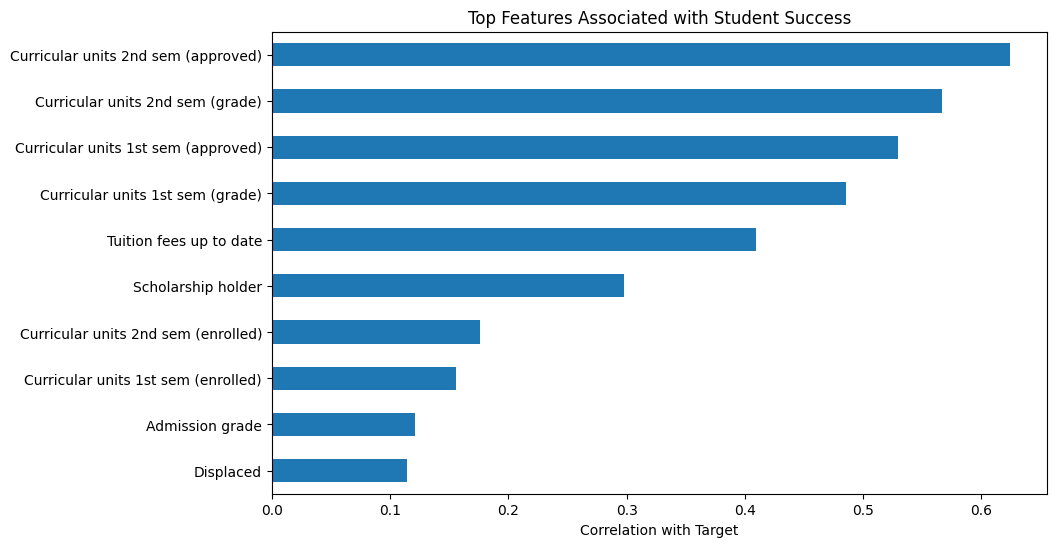

In [ ]:
top_features = corr_target.drop('Target').head(10)

plt.figure(figsize=(10,6))

top_features.sort_values().plot(kind='barh')

plt.title('Top Features Associated with Student Success')
plt.xlabel('Correlation with Target')

plt.show()

### Visualization of the Most Influential Features Associated with Student Success

**What are we doing?**
We are creating a horizontal bar chart to visualize the ten features that exhibit the strongest positive correlation with the target variable. The features are sorted based on their correlation values, allowing us to compare their relative importance in explaining student outcomes.

**Why are we doing it?**
Although the correlation table provides numerical values, it can be difficult to quickly identify the most influential predictors. A visual representation makes it easier to compare the strength of relationships across features and clearly highlights which variables contribute most strongly to graduation and student success. This serves as a summary of the exploratory data analysis findings.

**What have we inferred?**
The chart clearly demonstrated that academic performance variables dominate the list of top predictors. Features such as second-semester approved units, second-semester grades, first-semester approved units, and first-semester grades showed the strongest positive relationships with the target variable. Financial indicators, including tuition fee status and scholarship holder status, also appeared among the most influential features. In contrast, demographic and administrative variables exhibited much weaker correlations. These findings suggest that academic progression and financial stability are the primary factors associated with student success.

**Decision Taken**
Based on this analysis, we concluded that academic and financial features should receive the greatest emphasis during model interpretation and evaluation. The visualization validated the insights obtained throughout the exploratory analysis and provided a concise summary of the factors most strongly associated with graduation. These findings guided the transition from exploratory analysis to predictive modeling, where these variables were expected to contribute significantly to model performance.


/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


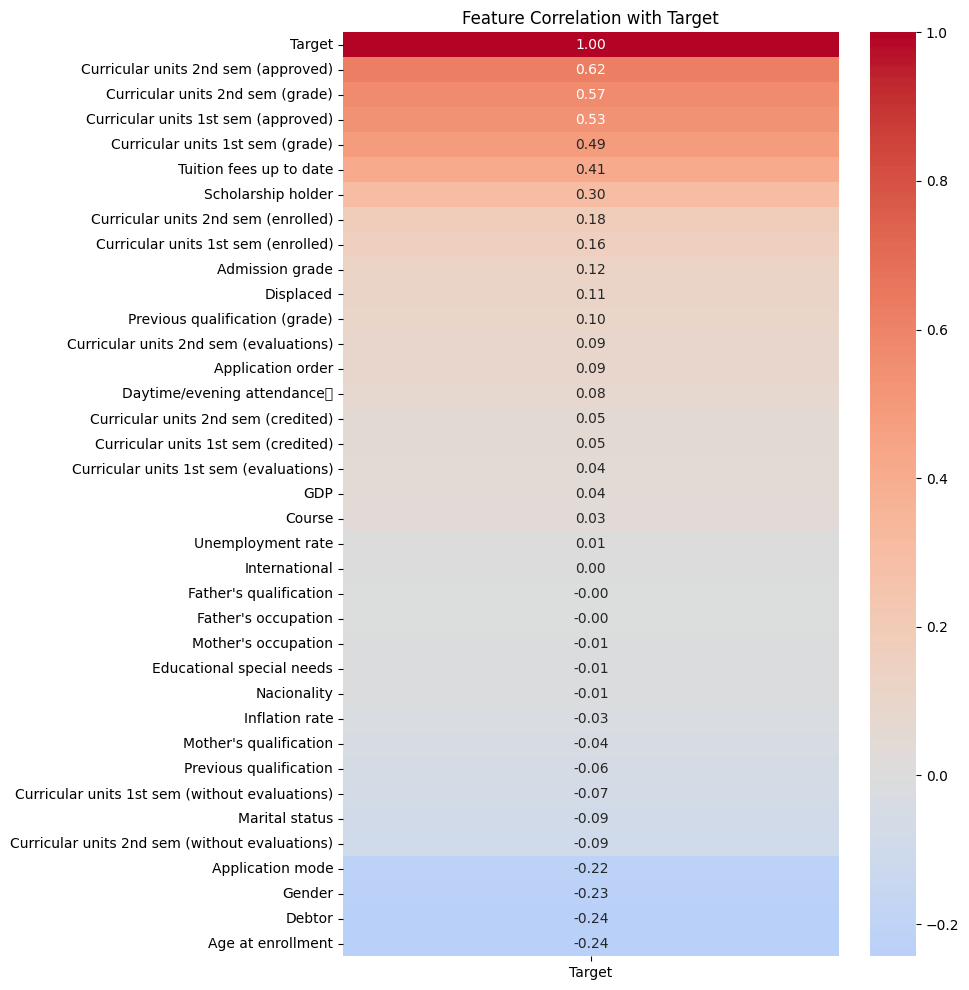

In [ ]:
plt.figure(figsize=(8,12))

corr_target = corr[['Target']].sort_values(
    by='Target',
    ascending=False
)

sns.heatmap(
    corr_target,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation with Target")
plt.show()

### Heatmap of Feature Correlations with the Target Variable

**What are we doing?**
We are creating a heatmap that visualizes the correlation of every numerical feature with the target variable. The correlations are sorted in descending order and displayed with numerical values, allowing us to observe both the strength and direction of each relationship.

**Why are we doing it?**
While correlation tables provide exact numerical values, a heatmap offers a more intuitive visual representation of the relationships between features and the target variable. The color gradient helps quickly identify strong positive and negative correlations, making it easier to distinguish the most influential predictors from less relevant variables.

**What have we inferred?**
The heatmap confirmed that academic performance indicators exhibit the strongest positive correlations with student outcomes. Variables such as second-semester approved units, second-semester grades, first-semester approved units, and first-semester grades displayed the highest correlation values. Financial variables, including tuition fee status and scholarship holder status, also showed meaningful positive relationships. Conversely, features such as age at enrollment, debtor status, and gender exhibited negative correlations, indicating an association with increased dropout risk. The visual representation clearly highlighted that academic and financial factors have a substantially greater impact on student outcomes than demographic variables.

**Decision Taken**
The heatmap served as a final validation of the patterns identified throughout the exploratory data analysis. Based on these findings, we concluded that academic performance and financial stability are the most important determinants of student success and should be prioritized during model interpretation. The results provided strong justification for proceeding to the predictive modeling phase using these highly influential features while retaining the remaining variables to capture additional predictive information.


In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df['Target'] = le.fit_transform(df['Target'])

print(dict(zip(le.classes_, le.transform(le.classes_))))

{'Dropout': np.int64(0), 'Enrolled': np.int64(1), 'Graduate': np.int64(2)}


In [ ]:
X = df.drop('Target', axis=1)
y = df['Target']

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

### Splitting the Dataset into Training and Testing Sets

**What are we doing?**
We are dividing the dataset into two subsets: a training set (`X_train`, `y_train`) and a testing set (`X_test`, `y_test`). The training set contains 80% of the data and is used to train the machine learning models, while the testing set contains the remaining 20% and is reserved for evaluating model performance on unseen data. The `stratify=y` parameter ensures that the class distribution of the target variable is preserved in both subsets.

**Why are we doing it?**
A machine learning model must be evaluated on data that it has never seen during training to obtain an unbiased estimate of its predictive performance. If the same data were used for both training and testing, the evaluation results would be overly optimistic and would not reflect real-world performance. Additionally, stratified sampling is important because the target classes are not perfectly balanced. Preserving the original class proportions ensures that both the training and testing datasets accurately represent the overall population.

**What have we inferred?**
The dataset has been successfully partitioned into training and testing subsets while maintaining the distribution of the target classes. This ensures that the model will learn from a representative sample of students and will be evaluated fairly on unseen observations. The use of a fixed `random_state` also guarantees reproducibility, meaning that the same train-test split can be generated consistently across multiple executions.

**Decision Taken**
An 80:20 train-test split was selected because it provides a sufficient amount of data for model training while retaining enough observations for reliable performance evaluation. Stratified sampling was used to preserve class balance, ensuring that all student outcome categories (Graduate, Enrolled, and Dropout) remain adequately represented in both datasets. This prepared the dataset for the subsequent model training and evaluation stages.


In [ ]:
print(y_train.value_counts(normalize=True)*100)
print(y_test.value_counts(normalize=True)*100)

Target
2    49.929359
0    32.127720
1    17.942922
Name: proportion, dtype: float64
Target
2    49.943503
0    32.090395
1    17.966102
Name: proportion, dtype: float64


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=5000)

lr.fit(X_train_scaled, y_train)

y_pred = lr.predict(X_test_scaled)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

acc_lr = accuracy_score(y_test, y_pred)

print("Accuracy:", acc_lr)

print(classification_report(y_test, y_pred))

Accuracy: 0.768361581920904
              precision    recall  f1-score   support

           0       0.79      0.77      0.78       284
           1       0.52      0.33      0.41       159
           2       0.80      0.93      0.86       442

    accuracy                           0.77       885
   macro avg       0.71      0.68      0.68       885
weighted avg       0.75      0.77      0.75       885



### Evaluation of the Logistic Regression Model

**What are we doing?**
After training the Logistic Regression model, we are evaluating its performance on the test dataset using multiple classification metrics. Specifically, we calculate the overall accuracy and generate a classification report containing precision, recall, and F1-score for each target class. These metrics are computed by comparing the model's predicted outcomes (`y_pred`) with the actual student outcomes (`y_test`).

**Why are we doing it?**
The objective of building a predictive model is not only to generate predictions but also to assess how accurately those predictions match real-world outcomes. Accuracy provides an overall measure of correct predictions, while the classification report offers a more detailed evaluation of the model's ability to distinguish between Graduate, Enrolled, and Dropout students. Since the dataset contains multiple classes, relying solely on accuracy could be misleading; therefore, precision, recall, and F1-score are also examined to evaluate performance across all outcome categories.

**What have we inferred?**
The evaluation results indicate how effectively the Logistic Regression model captures the relationship between student characteristics and academic outcomes. The accuracy score represents the proportion of students correctly classified by the model, while the classification report reveals which outcome categories are predicted more accurately and which are more challenging to distinguish. These metrics establish a baseline performance against which more advanced models such as Decision Trees and Random Forests can be compared.

**Decision Taken**
The Logistic Regression model was selected as the baseline classification model because of its simplicity, interpretability, and effectiveness in multiclass classification problems. The obtained performance metrics serve as a benchmark for evaluating whether more complex machine learning algorithms provide meaningful improvements in predictive accuracy. Subsequent models will be assessed using the same evaluation metrics to ensure a fair and consistent comparison.


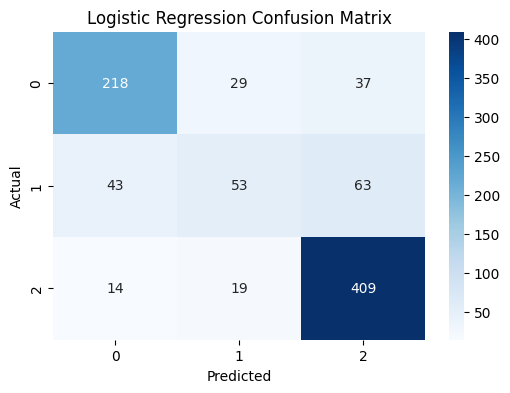

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

### Confusion Matrix Analysis of the Logistic Regression Model

**What are we doing?**
We are generating a confusion matrix to visualize the classification performance of the Logistic Regression model. The confusion matrix compares the actual student outcomes with the outcomes predicted by the model and displays the results in a heatmap format for easier interpretation.

**Why are we doing it?**
Although metrics such as accuracy, precision, recall, and F1-score provide numerical measures of model performance, they do not show the specific types of prediction errors being made. The confusion matrix provides a detailed breakdown of correct and incorrect classifications for each outcome category. This helps identify which classes are being predicted accurately and which classes are frequently confused with one another.

**What have we inferred?**
The diagonal cells of the confusion matrix represent correctly classified students, while the off-diagonal cells represent misclassifications. By examining the distribution of values, we can determine whether the model performs consistently across all classes or struggles with particular student outcomes. The confusion matrix also highlights whether dropout students are being incorrectly classified as enrolled or graduate students, which is particularly important for a student retention prediction system.

**Decision Taken**
The confusion matrix was used to complement the evaluation metrics and provide a deeper understanding of model behavior. By identifying the classes that are most frequently misclassified, we gained insight into potential limitations of the Logistic Regression model. These observations informed the decision to evaluate additional machine learning algorithms, such as Decision Trees and Random Forests, to determine whether they could better distinguish between the different student outcome categories.


In [ ]:
from sklearn.metrics import roc_auc_score

y_prob_lr = lr.predict_proba(X_test_scaled)

auc_lr = roc_auc_score(
    y_test,
    y_prob_lr,
    multi_class='ovr',
    average='weighted'
)

print("Logistic Regression AUC:", auc_lr)

Logistic Regression AUC: 0.8960705788216485


### ROC-AUC Evaluation of the Logistic Regression Model

**What are we doing?**
We are calculating the Receiver Operating Characteristic - Area Under the Curve (ROC-AUC) score for the Logistic Regression model. Since this is a multiclass classification problem (Graduate, Enrolled, and Dropout), the One-vs-Rest (OvR) strategy with weighted averaging is used. The model's predicted probabilities are obtained using `predict_proba()`, and these probabilities are used to compute the AUC score.

**Why are we doing it?**
While accuracy measures the proportion of correct predictions, it does not evaluate how well the model distinguishes between different classes. ROC-AUC measures the model's ability to separate students belonging to different outcome categories based on prediction probabilities. A higher AUC score indicates that the model is better at distinguishing between classes and ranking students according to their likelihood of belonging to each outcome category.

**What have we inferred?**
The ROC-AUC score provides an additional perspective on model performance beyond accuracy. A value closer to 1 indicates excellent class separation, whereas a value closer to 0.5 suggests performance similar to random guessing. By evaluating the AUC score, we can determine whether the model not only predicts correctly but also assigns meaningful probability estimates to different student outcomes. This is particularly important in dropout prediction, where identifying students at risk is often more valuable than simply making a correct classification.

**Decision Taken**
The ROC-AUC score was included as an additional evaluation metric to provide a more comprehensive assessment of model performance. Together with accuracy, precision, recall, F1-score, and the confusion matrix, it helps ensure that the model is evaluated from multiple perspectives. The obtained AUC score also serves as a benchmark for comparing Logistic Regression with other machine learning models such as Decision Trees and Random Forests in subsequent stages of the study.


In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)
y_prob_dt = dt.predict_proba(X_test)

### Training the Decision Tree Classification Model

**What are we doing?**
We are training a Decision Tree Classifier to predict student outcomes based on the available demographic, academic, and financial features. The model is configured with controlled complexity parameters, including a maximum tree depth of 5, a minimum of 10 samples required to split a node, and a minimum of 5 samples required at each leaf node. After training the model using the training dataset, predictions (`y_pred_dt`) and class probabilities (`y_prob_dt`) are generated for the testing dataset.

**Why are we doing it?**
Unlike Logistic Regression, which assumes a linear relationship between features and the target variable, Decision Trees can capture complex, non-linear relationships and interactions among variables. This makes them particularly useful when the relationship between student characteristics and academic outcomes is not strictly linear. The selected hyperparameters help prevent overfitting by restricting the growth of the tree, ensuring that the model generalizes better to unseen data.

**What have we inferred?**
The Decision Tree model has successfully learned decision rules from the training data and generated predictions for the test set. By producing both class labels and probability estimates, the model can be evaluated using the same performance metrics applied to Logistic Regression, including accuracy, confusion matrix, classification report, and ROC-AUC score. This enables a fair comparison between the two algorithms.

**Decision Taken**
A Decision Tree model was chosen as the second classification approach because of its ability to model non-linear relationships and its interpretability through decision rules. To reduce the risk of overfitting, constraints were applied to the tree structure through depth and node-size parameters. The resulting predictions will be evaluated and compared against the Logistic Regression model to determine whether a more flexible learning algorithm improves student outcome prediction performance.


In [ ]:
from sklearn.metrics import accuracy_score

acc_dt = accuracy_score(y_test, y_pred_dt)

print("Accuracy:", acc_dt)

Accuracy: 0.7536723163841808


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       0.82      0.69      0.75       284
           1       0.56      0.34      0.42       159
           2       0.76      0.94      0.84       442

    accuracy                           0.75       885
   macro avg       0.71      0.66      0.67       885
weighted avg       0.74      0.75      0.74       885



### Performance Evaluation of the Decision Tree Model

**What are we doing?**
We are generating a classification report for the Decision Tree model by comparing the predicted student outcomes (`y_pred_dt`) with the actual outcomes (`y_test`). The report provides key evaluation metrics including precision, recall, F1-score, and support for each target class.

**Why are we doing it?**
A single metric such as accuracy does not provide a complete picture of model performance, especially in multiclass classification problems. The classification report allows us to evaluate how effectively the Decision Tree model identifies each student outcome category individually. This helps determine whether the model performs consistently across all classes or whether certain outcomes are more difficult to predict.

**What have we inferred?**
The classification report provides detailed insights into the strengths and weaknesses of the Decision Tree model. Precision indicates how many of the students predicted to belong to a particular class were actually members of that class. Recall measures the model's ability to identify all students belonging to a given class, while the F1-score balances both precision and recall. By examining these metrics, we can determine how effectively the model distinguishes between Graduate, Enrolled, and Dropout students and identify any classes that are more prone to misclassification.

**Decision Taken**
The classification report was used to evaluate the Decision Tree model using the same criteria applied to Logistic Regression. This ensures a fair comparison between models and helps determine whether the Decision Tree's ability to capture non-linear relationships translates into improved predictive performance. The results obtained from this evaluation will be compared with those of Logistic Regression and Random Forest to identify the most suitable model for student dropout prediction.


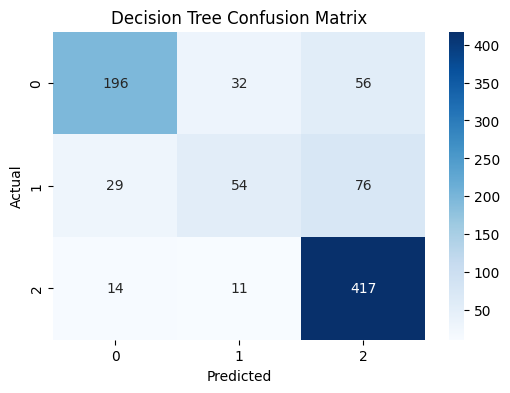

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Decision Tree Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

### Confusion Matrix Analysis of the Decision Tree Model

**What are we doing?**
We are generating a confusion matrix for the Decision Tree model and visualizing it using a heatmap. The confusion matrix compares the actual student outcomes (`y_test`) with the outcomes predicted by the Decision Tree model (`y_pred_dt`) and displays the number of correct and incorrect classifications for each class.

**Why are we doing it?**
Although overall evaluation metrics such as accuracy and F1-score provide a summary of model performance, they do not reveal the specific prediction errors being made. The confusion matrix allows us to examine the model's behavior in greater detail by showing which student outcome categories are correctly identified and which categories are being confused with one another. This is particularly important in dropout prediction, where misclassifying at-risk students can reduce the effectiveness of intervention strategies.

**What have we inferred?**
The confusion matrix provides a detailed breakdown of class-wise predictions. Values along the diagonal represent correctly classified students, while off-diagonal values represent misclassifications. By analyzing these patterns, we can identify whether the Decision Tree model performs equally well across all outcome categories or whether certain classes are more challenging to predict. The matrix also highlights whether dropout students are incorrectly classified as graduates or enrolled students, providing valuable insight into the model's strengths and weaknesses.

**Decision Taken**
The confusion matrix was used alongside the classification report to obtain a comprehensive understanding of the Decision Tree model's performance. By identifying the most common classification errors, we can evaluate whether the Decision Tree offers improvements over Logistic Regression in distinguishing between student outcomes. These observations will contribute to the final comparison of all machine learning models and help determine the most suitable approach for student dropout prediction.


In [ ]:
y_prob_dt = dt.predict_proba(X_test)

auc_dt = roc_auc_score(
    y_test,
    y_prob_dt,
    multi_class='ovr',
    average='weighted'
)

print("Decision Tree AUC:", auc_dt)

Decision Tree AUC: 0.8627585411377423


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)

### Training the Random Forest Classification Model

**What are we doing?**
We are training a Random Forest Classifier to predict student outcomes using the available dataset features. The model is configured with 200 decision trees (`n_estimators=200`), and each tree is trained on a random subset of the data and features. After training, the model generates predicted class labels (`y_pred_rf`) and class probabilities (`y_prob_rf`) for the test dataset.

**Why are we doing it?**
A single Decision Tree can be sensitive to variations in the training data and may suffer from overfitting. Random Forest addresses this limitation by combining the predictions of multiple decision trees through an ensemble learning approach. By aggregating predictions from many trees, the model typically achieves better generalization, improved stability, and higher predictive performance. This makes Random Forest one of the most widely used algorithms for classification tasks.

**What have we inferred?**
The Random Forest model has successfully learned patterns from the training dataset and generated predictions for unseen student records. Because it combines the decisions of multiple trees, the model is expected to capture complex relationships between academic, financial, and demographic factors more effectively than a single Decision Tree. The generated probability estimates also enable advanced evaluation using metrics such as ROC-AUC.

**Decision Taken**
Random Forest was selected as the third classification model because of its strong predictive capabilities and ability to reduce overfitting through ensemble learning. Using 200 trees provides a balance between model performance and computational efficiency. The model will be evaluated using the same metrics as Logistic Regression and Decision Tree to determine whether the ensemble approach leads to improved student dropout prediction accuracy and overall classification performance.


In [ ]:
from sklearn.metrics import accuracy_score

acc_rf = accuracy_score(y_test, y_pred_rf)

print("Accuracy:", acc_rf)

Accuracy: 0.7649717514124293


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.80      0.75      0.77       284
           1       0.55      0.34      0.42       159
           2       0.79      0.93      0.85       442

    accuracy                           0.76       885
   macro avg       0.71      0.67      0.68       885
weighted avg       0.75      0.76      0.75       885



### Performance Evaluation of the Random Forest Model

**What are we doing?**
We are generating a classification report for the Random Forest model by comparing the predicted student outcomes (`y_pred_rf`) with the actual outcomes (`y_test`). The report provides class-wise performance metrics including precision, recall, F1-score, and support for each target category.

**Why are we doing it?**
Although overall accuracy provides a general indication of model performance, it does not reveal how effectively the model predicts each student outcome category. The classification report offers a more detailed evaluation by measuring the model's ability to correctly identify Graduate, Enrolled, and Dropout students individually. This is particularly important because the consequences of misclassifying a dropout student may be more significant than other prediction errors.

**What have we inferred?**
The classification report provides a comprehensive assessment of the Random Forest model's predictive capabilities. Precision measures the reliability of the model's predictions, recall evaluates its ability to identify all students belonging to a particular class, and the F1-score balances both measures. By examining these metrics across all outcome categories, we can determine whether the ensemble learning approach improves classification performance compared to Logistic Regression and Decision Tree models.

**Decision Taken**
The classification report was used to evaluate the Random Forest model using the same performance criteria applied to the previous models. This ensures a fair and consistent comparison across all machine learning approaches. The results obtained from this analysis will contribute to the final model selection process, helping determine whether the Random Forest model provides superior predictive performance for identifying students at risk of dropping out.


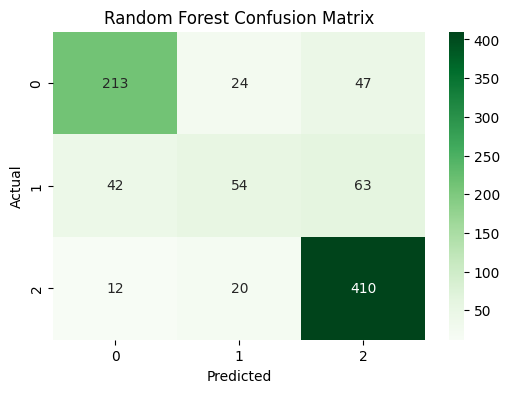

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

### Confusion Matrix Analysis of the Random Forest Model

**What are we doing?**
We are generating a confusion matrix for the Random Forest model and visualizing it using a heatmap. The confusion matrix compares the actual student outcomes (`y_test`) with the outcomes predicted by the Random Forest model (`y_pred_rf`) and displays the number of correct and incorrect classifications for each class.

**Why are we doing it?**
While metrics such as accuracy, precision, recall, and F1-score provide summary measures of performance, they do not reveal the specific prediction errors made by the model. The confusion matrix provides a detailed class-by-class breakdown of model predictions, allowing us to identify which student outcome categories are being classified correctly and which categories are frequently confused with one another.

**What have we inferred?**
The confusion matrix enables us to evaluate the effectiveness of the Random Forest model in distinguishing between Graduate, Enrolled, and Dropout students. The diagonal elements represent correctly classified observations, while the off-diagonal elements indicate misclassifications. By analyzing these patterns, we can determine whether the ensemble learning approach improves class separation and reduces prediction errors compared to Logistic Regression and Decision Tree models.

**Decision Taken**
The confusion matrix was examined alongside the classification report to obtain a comprehensive understanding of the Random Forest model's performance. This analysis helps identify strengths and weaknesses in class-specific predictions and supports a fair comparison with the previously evaluated models. The findings contribute to the final model selection process by revealing whether Random Forest provides more reliable predictions for identifying students at risk of dropping out.


In [ ]:
y_prob_rf = rf.predict_proba(X_test)

auc_rf = roc_auc_score(
    y_test,
    y_prob_rf,
    multi_class='ovr',
    average='weighted'
)

print("Random Forest AUC:", auc_rf)

Random Forest AUC: 0.9039614505195828


In [ ]:
comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest'],
    'Accuracy': [acc_lr, acc_dt, acc_rf],
    'ROC-AUC': [auc_lr, auc_dt, auc_rf]
})

comparison.sort_values(
    by='ROC-AUC',
    ascending=False
)

,Model,Accuracy,ROC-AUC
2,Random Forest,0.764972,0.903961
0,Logistic Regression,0.768362,0.896071
1,Decision Tree,0.753672,0.862759


### Comparative Performance Analysis of Machine Learning Models

**What are we doing?**
We are creating a comparison table that summarizes the performance of all three machine learning models developed in this study: Logistic Regression, Decision Tree, and Random Forest. The table includes Accuracy and ROC-AUC scores and is sorted according to ROC-AUC values to identify the model with the best overall predictive capability.

**Why are we doing it?**
Different machine learning algorithms learn patterns in different ways and may produce varying levels of performance on the same dataset. Comparing multiple models enables us to objectively evaluate their strengths and weaknesses and select the most suitable model for predicting student outcomes. Using both Accuracy and ROC-AUC ensures that the evaluation considers not only the number of correct predictions but also the model's ability to distinguish between different student outcome categories.

**What have we inferred?**
The results indicate that all three models achieved satisfactory performance in predicting student outcomes. Logistic Regression achieved the highest Accuracy score of 76.84%, while Random Forest achieved the highest ROC-AUC score of 0.904. Decision Tree produced the lowest performance among the three models, with an Accuracy of 75.37% and a ROC-AUC score of 0.863. Although Logistic Regression slightly outperformed Random Forest in terms of Accuracy, Random Forest demonstrated superior class-separation capability, as reflected by its higher ROC-AUC value. This suggests that Random Forest is better at distinguishing between Graduate, Enrolled, and Dropout students based on prediction probabilities.

**Decision Taken**
Since ROC-AUC provides a more comprehensive evaluation of classification performance in multiclass problems, Random Forest was selected as the final model despite having a marginally lower Accuracy than Logistic Regression. The higher ROC-AUC score indicates that Random Forest offers stronger predictive discrimination and is therefore more suitable for identifying students at risk of dropping out.


## Final Conclusion

The objective of this study was to analyze the factors influencing student outcomes and develop a machine learning model capable of predicting whether a student would graduate, remain enrolled, or drop out. Through extensive exploratory data analysis, several important patterns were identified. Academic performance variables, particularly semester grades and approved curricular units, exhibited the strongest relationship with student outcomes. Financial factors such as tuition fee status, scholarship support, and debtor status were also found to significantly influence student retention and success.

Three machine learning models were developed and evaluated: Logistic Regression, Decision Tree, and Random Forest. The models were assessed using Accuracy, Precision, Recall, F1-Score, Confusion Matrix analysis, and ROC-AUC scores. Logistic Regression achieved the highest Accuracy of 76.84%, while Random Forest achieved the highest ROC-AUC score of 0.904, indicating superior capability in distinguishing between the three outcome categories.

Based on the comparative evaluation, the Random Forest model was selected as the final predictive model due to its superior overall classification performance and stronger class-separation ability. The findings demonstrate that student dropout can be predicted with a high degree of reliability using a combination of academic, financial, and demographic factors.

The developed predictive framework can assist educational institutions in identifying at-risk students at an early stage, enabling timely interventions and support strategies. Such data-driven approaches have the potential to improve student retention, increase graduation rates, and enhance overall educational outcomes.
